# 17 - Visualization Masterclass

**Part B - Petrophys Curriculum**

`petrophys.visualization` is a full plotting suite, not a single `plot()` call. This
notebook is the **gallery**: we render every major figure type on real wells and briefly
explain what each is for and when to reach for it. Treat it as a visual index you can
return to when you need the right plot for a task.

## Learning goals

- Drive the **XML-template log viewer** (`create_log_viewer`) with named templates,
  the `auto`/adaptive template, and `DEFAULT_LOG_VIEWER_TEMPLATES`.
- Render the **triple combo** (`create_triple_combo`) - the standard first-look display.
- Work through the **crossplot family**: `create_nd_crossplot`, `create_pickett_plot`,
  `create_mn_plot`, `create_mid_plot`, `create_buckles_plot`, `create_hingle_plot`.
- Use the **specialist panels**: `create_nmr_panel`, `create_fmi_panel`,
  `create_flow_unit_plot`.
- Overlay **zone flags** and **formation shading** (`plot_zone_flags`, `add_zone_shading`).

## Why this matters

Petrophysical interpretation is a visual discipline. The same numbers tell different
stories depending on the axes you put them on: a Pickett plot exposes the water line and
cementation exponent; an N-D crossplot separates lithology and gas; a Buckles plot tests
whether a zone is at irreducible water. Knowing which figure answers which question - and
letting the library build it from a template - is most of the craft.

### Prerequisites

Assumes the Part A workflow notebooks (you should recognise `PHIE`, `SW`, `PERM`, and the
`NET_ROCK/NET_RES/NET_PAY` flags). We run the standard workflow once up front so every
well carries a full interpreted curve set for the plots to draw.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.workflow import BatchProcessor
from petrophys import visualization as V
from petrophys.visualization import (
    create_log_viewer, DEFAULT_LOG_VIEWER_TEMPLATES,
    create_adaptive_log_viewer_template,
    create_triple_combo,
    create_nd_crossplot, create_pickett_plot,
    create_mn_plot, create_mid_plot,
    create_buckles_plot, create_hingle_plot,
    create_nmr_panel, create_fmi_panel, create_flow_unit_plot,
    plot_zone_flags, add_zone_shading,
)
from petrophys.visualization.specialist_panels import has_nmr_curves
from petrophys.reservoir import calculate_flow_units

print("petrophys", petrophys.__version__)
print("named templates:", list(DEFAULT_LOG_VIEWER_TEMPLATES.keys()))

petrophys 0.1.0
named templates: ['raw', 'triple_combo', 'comprehensive', 'full', 'petrophysics', 'interpretation', 'minerals', 'geolink', 'geolink_full', 'standard', 'universal']


### Load and interpret the teaching wells

We use two contrasting wells:

- **30/6-5** - a North Sea **clastic** well with a rich curve set and a vendor
  `LITHOLOGY_GEOLINK` log (depth in metres).
- **HW-3** - a **carbonate** well from the Costa field (depth in feet).

Running `BatchProcessor` with its default standard workflow adds `VCL`, `PHIE`, `SW`,
`PERM`, and net-pay flags to each.

In [2]:
bp = BatchProcessor()

geo = read_las(petrophys.sample("30_6-5"))
geo = bp.process_wells([geo])[0].result.well

carb = read_las(petrophys.sample("HW-3"))
carb = bp.process_wells([carb])[0].result.well

def sanitize(s):
    return str(s).encode("ascii", "replace").decode("ascii")

print("30/6-5 :", geo.n_samples, "samples,", geo.depth_unit,
      "| field:", sanitize(geo.header.field))
print("HW-3   :", carb.n_samples, "samples,", carb.depth_unit)
print("30/6-5 interpreted curves present:",
      [c for c in ("VCL", "PHIE", "SW", "PERM", "NET_PAY") if geo.has_curve(c)])

# Reusable working intervals on 30/6-5:
GEO_FULL = (2600.0, 3200.0)     # broad reservoir section
GEO_LITH = (2784.0, 3176.0)     # PEF live here -> lithology crossplots
GEO_WATER = (3223.0, 3556.0)    # Statfjord water-bearing sand -> Pickett/Hingle

30/6-5 : 22176 samples, m | field: OSEBERG ??ST
HW-3   : 431 samples, ft
30/6-5 interpreted curves present: ['VCL', 'PHIE', 'SW', 'PERM', 'NET_PAY']


## 1. Template log viewer

`create_log_viewer` builds a multi-track figure from a PetroPy-style **XML template**.
You can pass a named built-in template via `template_defaults=...` or let it choose one
automatically with `"auto"`. The available names are the keys of
`DEFAULT_LOG_VIEWER_TEMPLATES` (several are aliases pointing at the same XML).

The viewer returns a `LogViewer` object; call `.create(depth_range=...)` to get
`(fig, axes)`, then `.close()` when done (or `.save(path)` / `.show()`).

geolink_full template -> 9 tracks


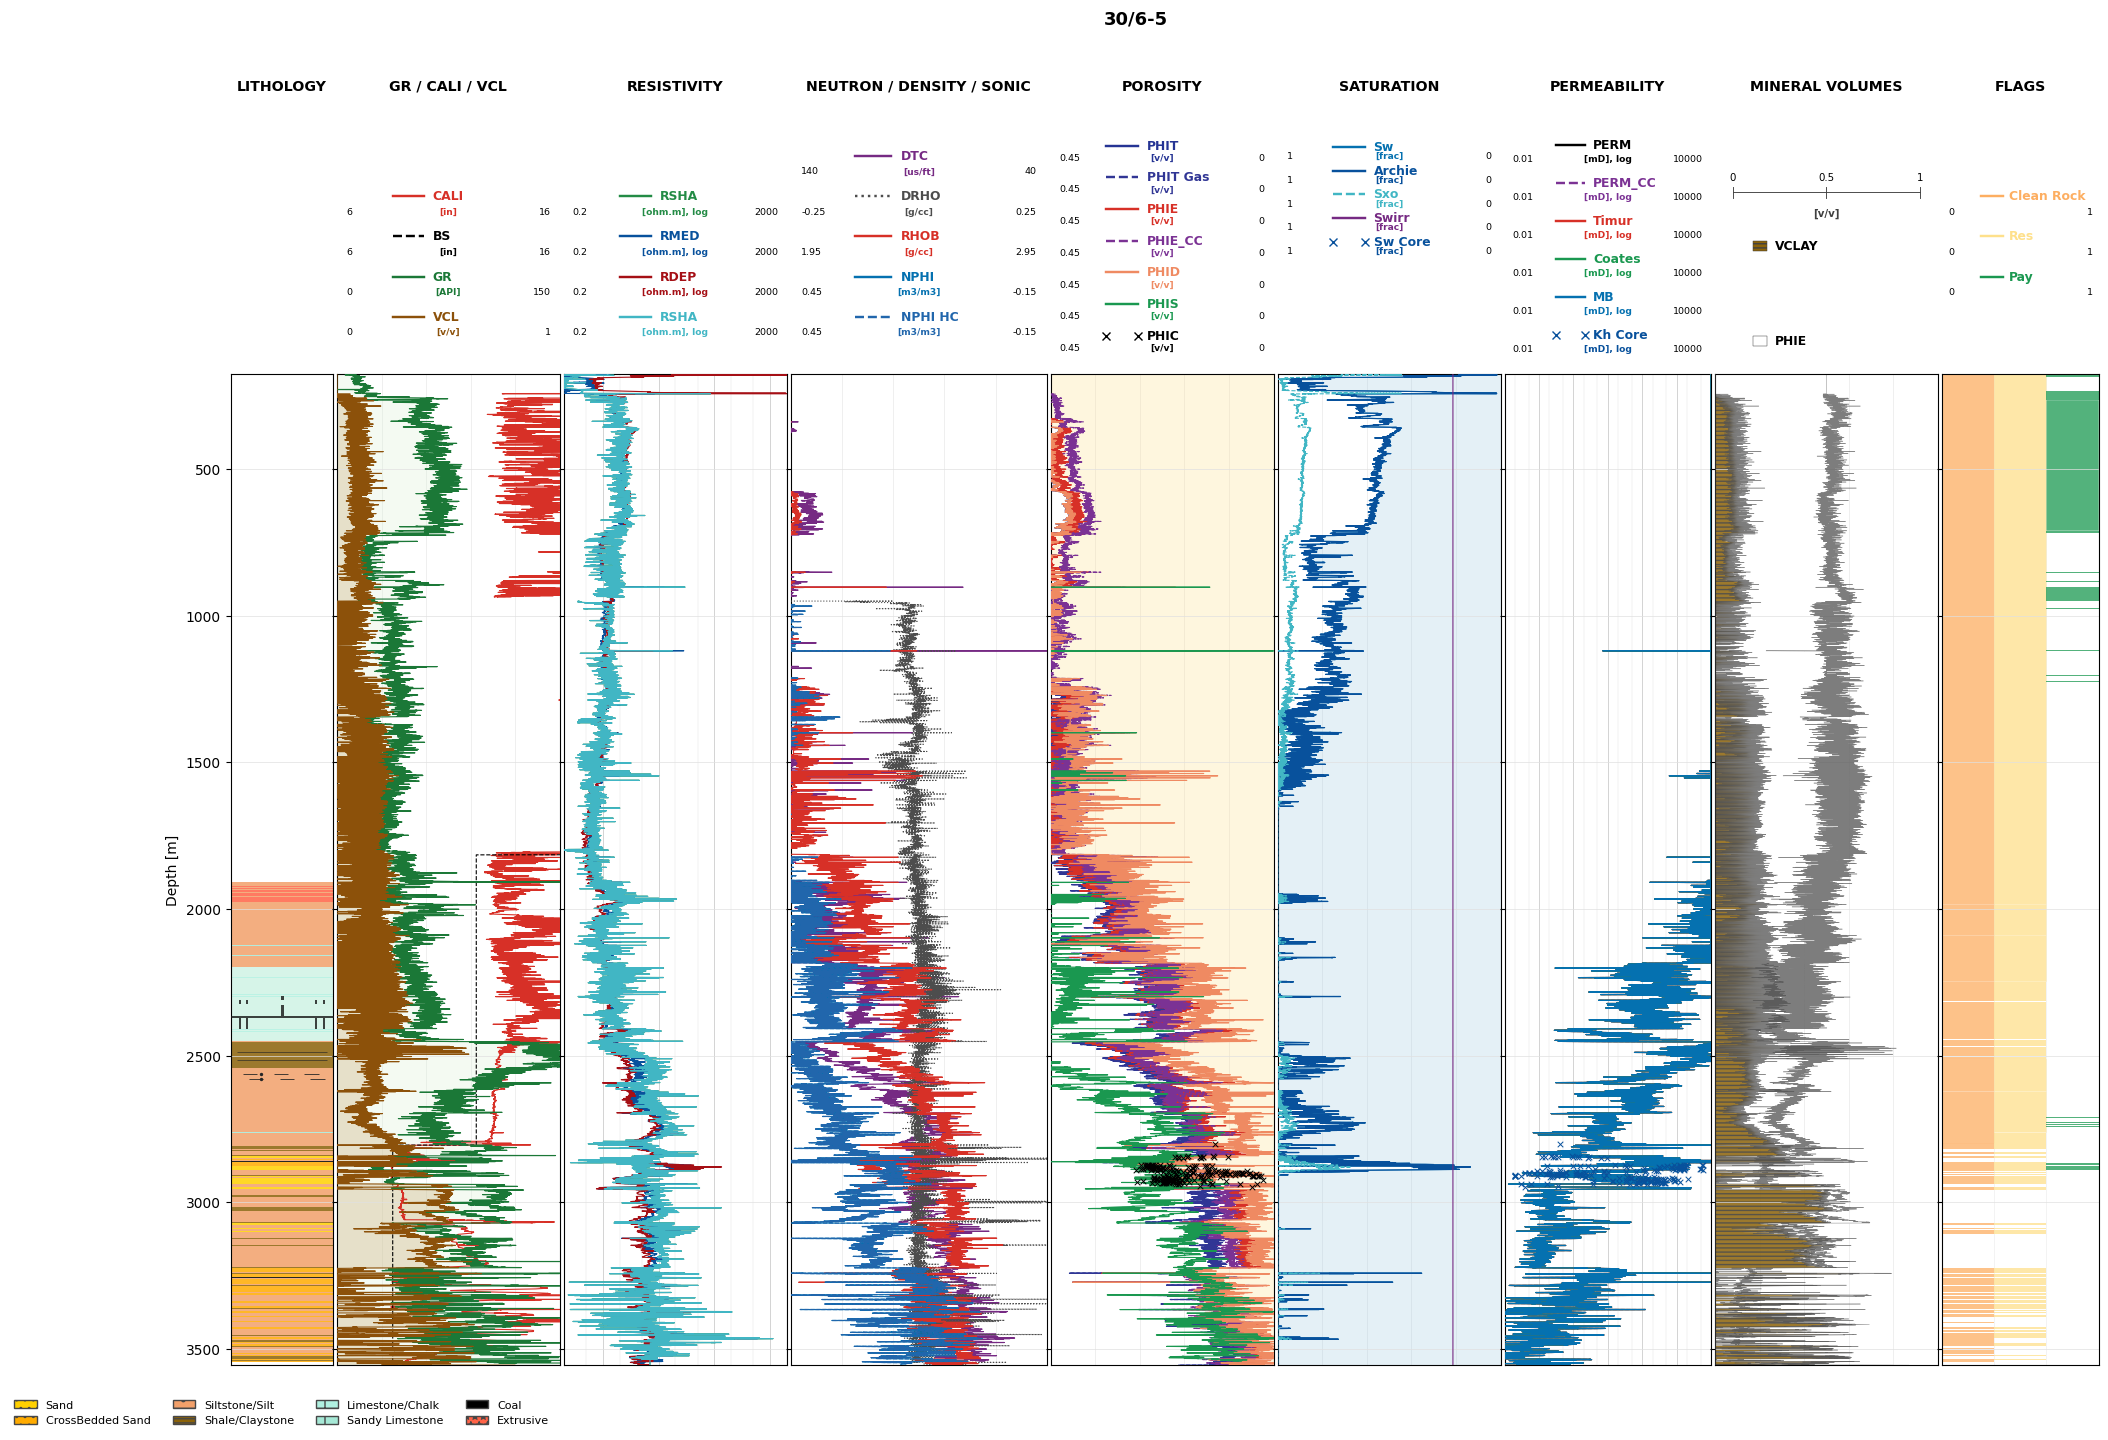

In [3]:
viewer = create_log_viewer(geo, template_defaults="geolink_full", depth_range=GEO_FULL)
fig, axes = viewer.create()
print("geolink_full template ->", len(axes), "tracks")
plt.show()
viewer.close()

### The adaptive `auto` template

`template_defaults="auto"` inspects the curves actually present and assembles tracks on
the fly (gamma/hole, resistivity, density-neutron, porosity, saturation, permeability,
flags, ...), skipping any family the well lacks. This is the safe default for an unknown
LAS. `create_adaptive_log_viewer_template` exposes that template object directly so you
can see what it decided.

adaptive template tracks:
  DEPTH              []
  LITHOLOGY          ['LITHOLOGY_GEOLINK']
  GAMMA / HOLE       ['GR', 'VCL', 'CALI', 'BS']
  RESISTIVITY        ['RDEP', 'RMED', 'RSHA']
  DENSITY / NEUTRON  ['DTC', 'RHOB', 'NPHI', 'DRHO', 'PEF']
  POROSITY           ['PHIT', 'PHIE', 'PHIE_CC', 'PHID', 'PHIS', 'PHIN', 'PHIC']
  SATURATION         ['SW', 'SXO', 'SWIRR_APP', 'SWC']
  PERMEABILITY       ['PERM', 'PERM_CC', 'KH_CORE']
  FLAGS              ['NET_ROCK', 'NET_RES', 'NET_PAY']


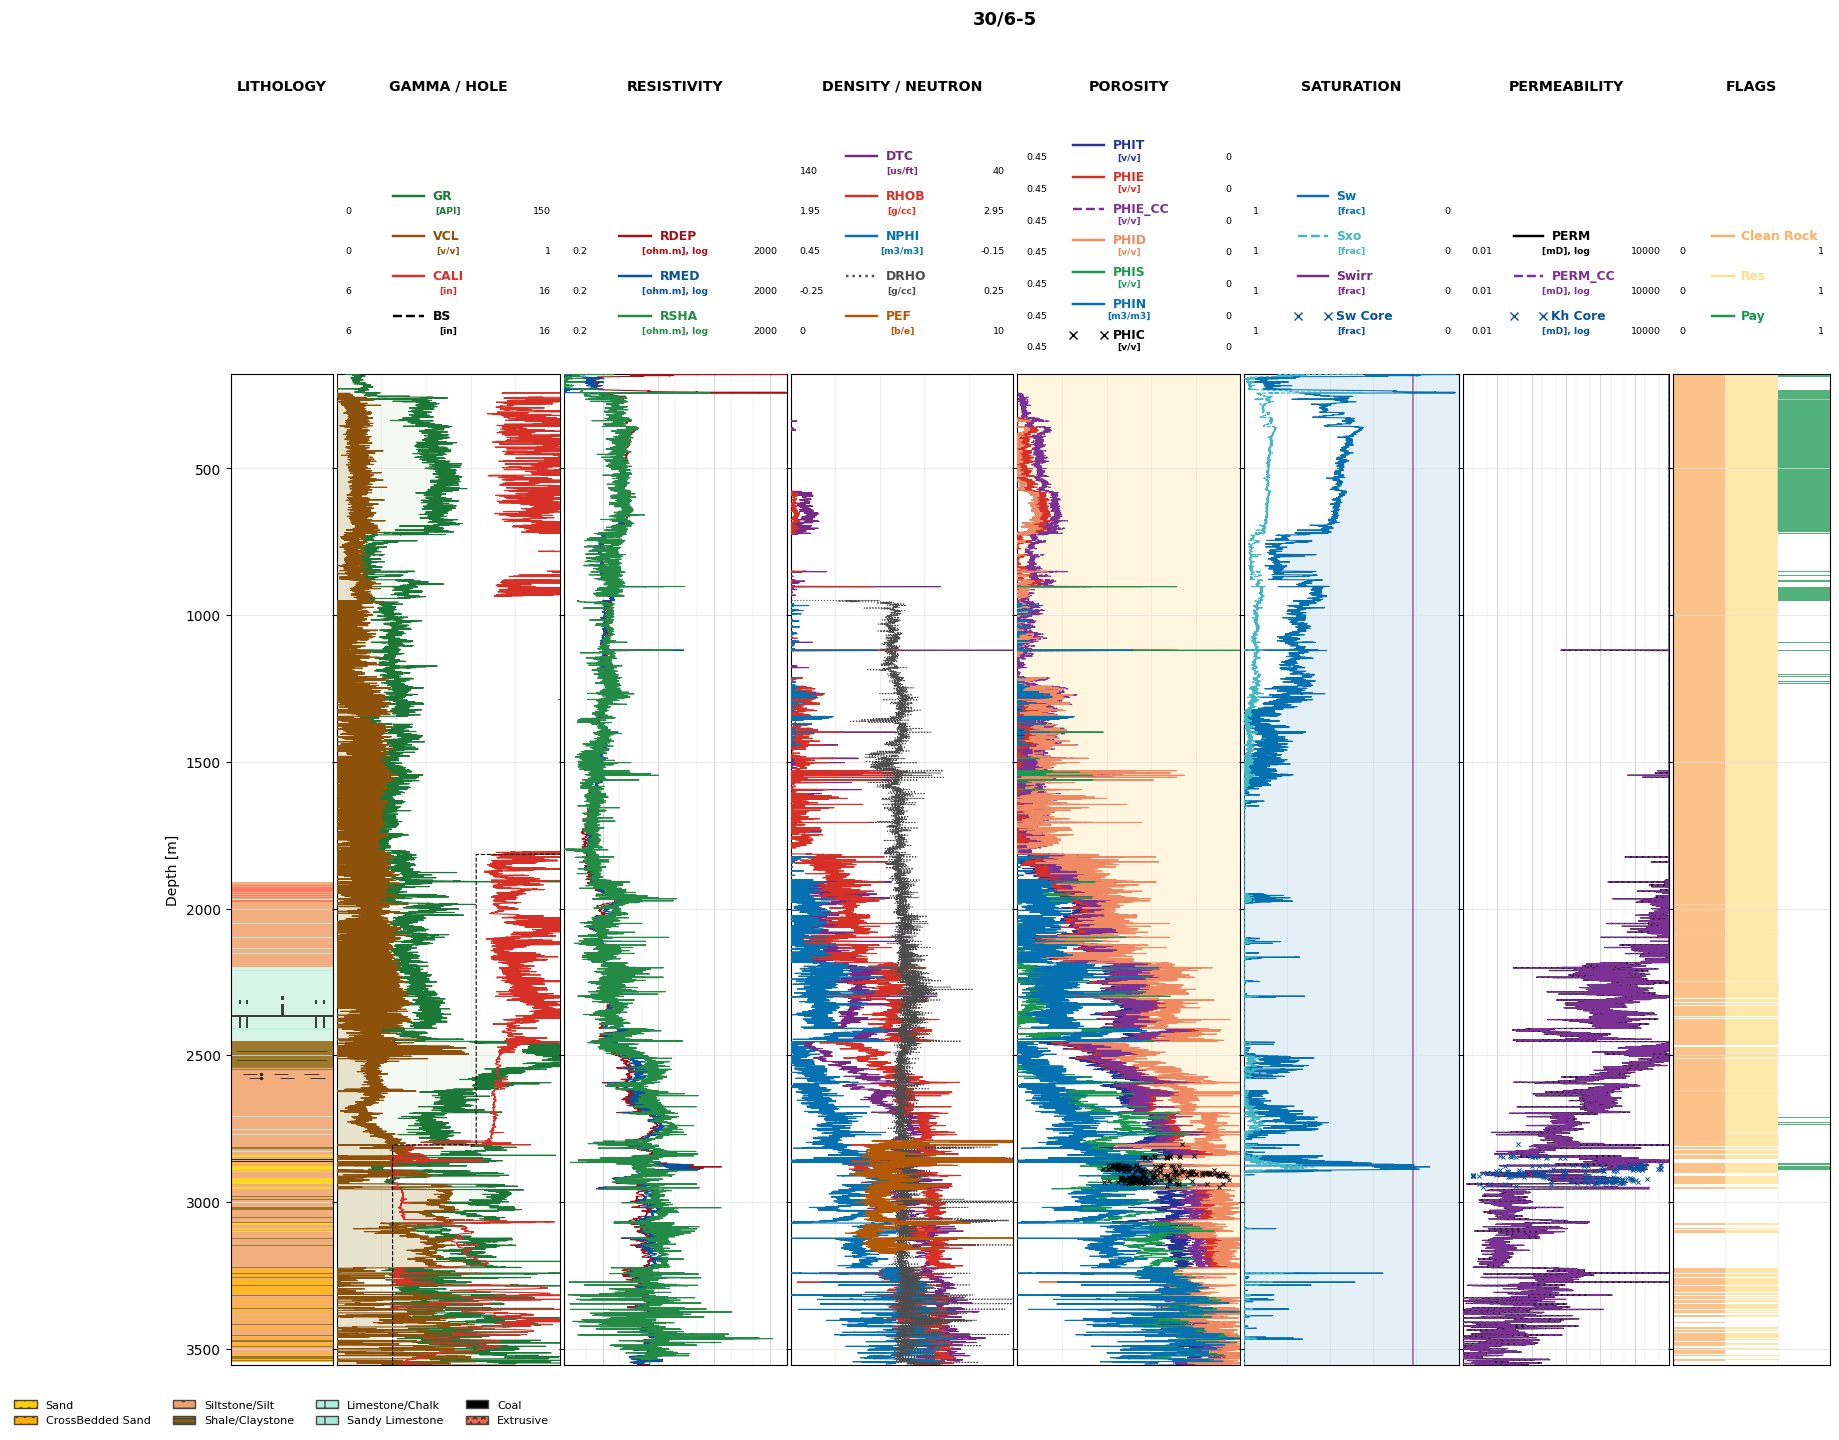

In [4]:
tmpl = create_adaptive_log_viewer_template(geo)
print("adaptive template tracks:")
for t in tmpl.tracks:
    curves = [c.curve_name for c in t.curves]
    print("  %-18s %s" % (t.display_name, curves))

viewer = create_log_viewer(geo, template_defaults="auto", depth_range=GEO_FULL)
fig, axes = viewer.create()
plt.show()
viewer.close()

The same `auto` template adapts to the carbonate well, which has fewer curves and no
vendor lithology log - note the different track set it produces.

HW-3 auto -> 9 tracks


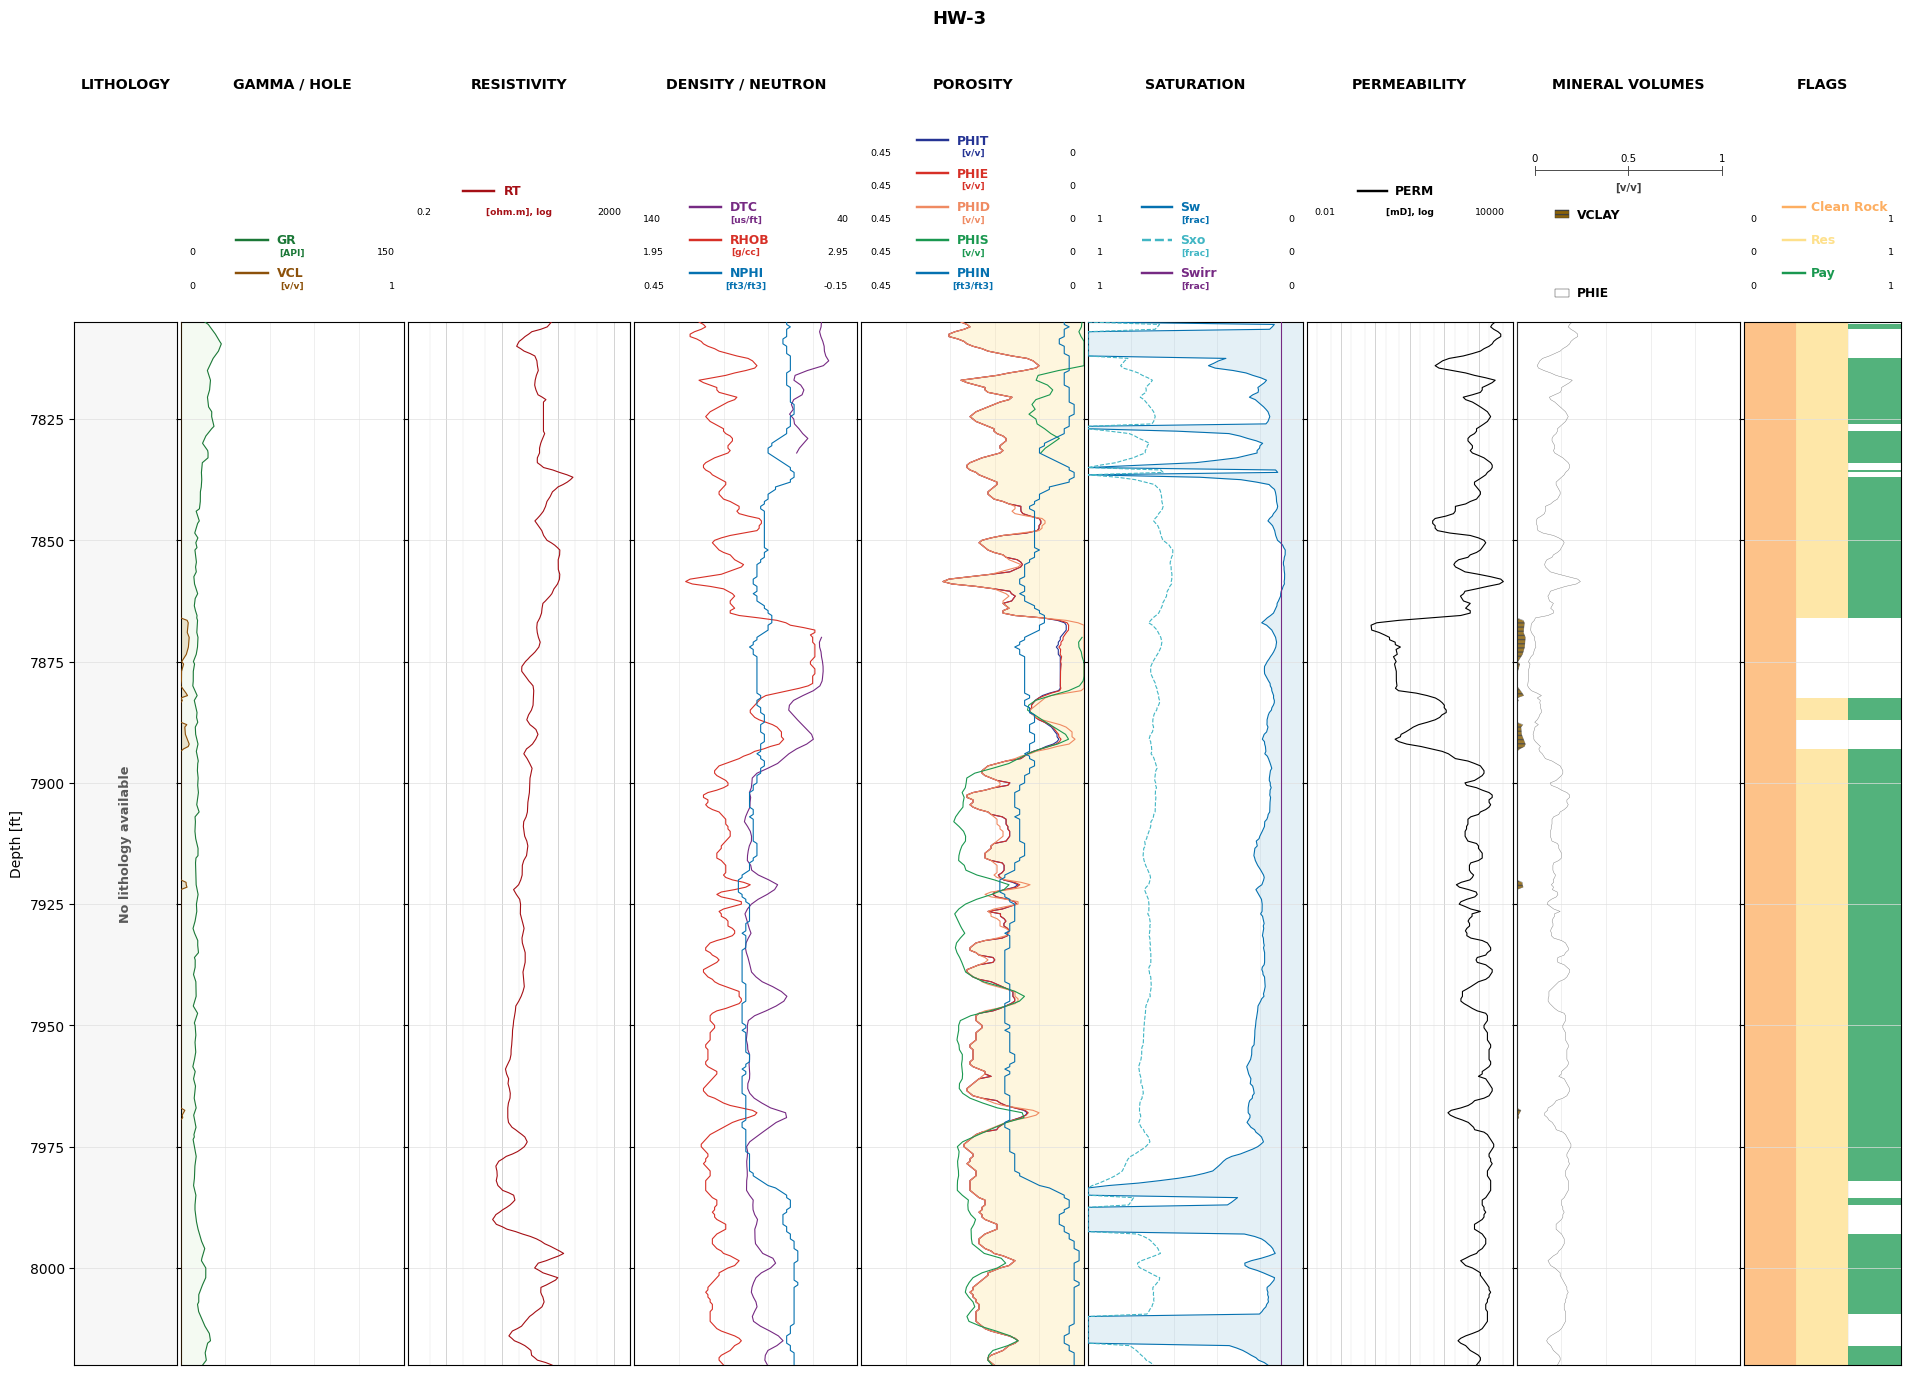

In [5]:
viewer = create_log_viewer(carb, template_defaults="auto")
fig, axes = viewer.create()
print("HW-3 auto ->", len(axes), "tracks")
plt.show()
viewer.close()

## 2. Triple combo

`create_triple_combo` is the classic three-panel first look: gamma/caliper,
resistivity (log scale), and density-neutron. It is the fastest way to eyeball reservoir
vs seal and hydrocarbon crossover. One call, sensible defaults.

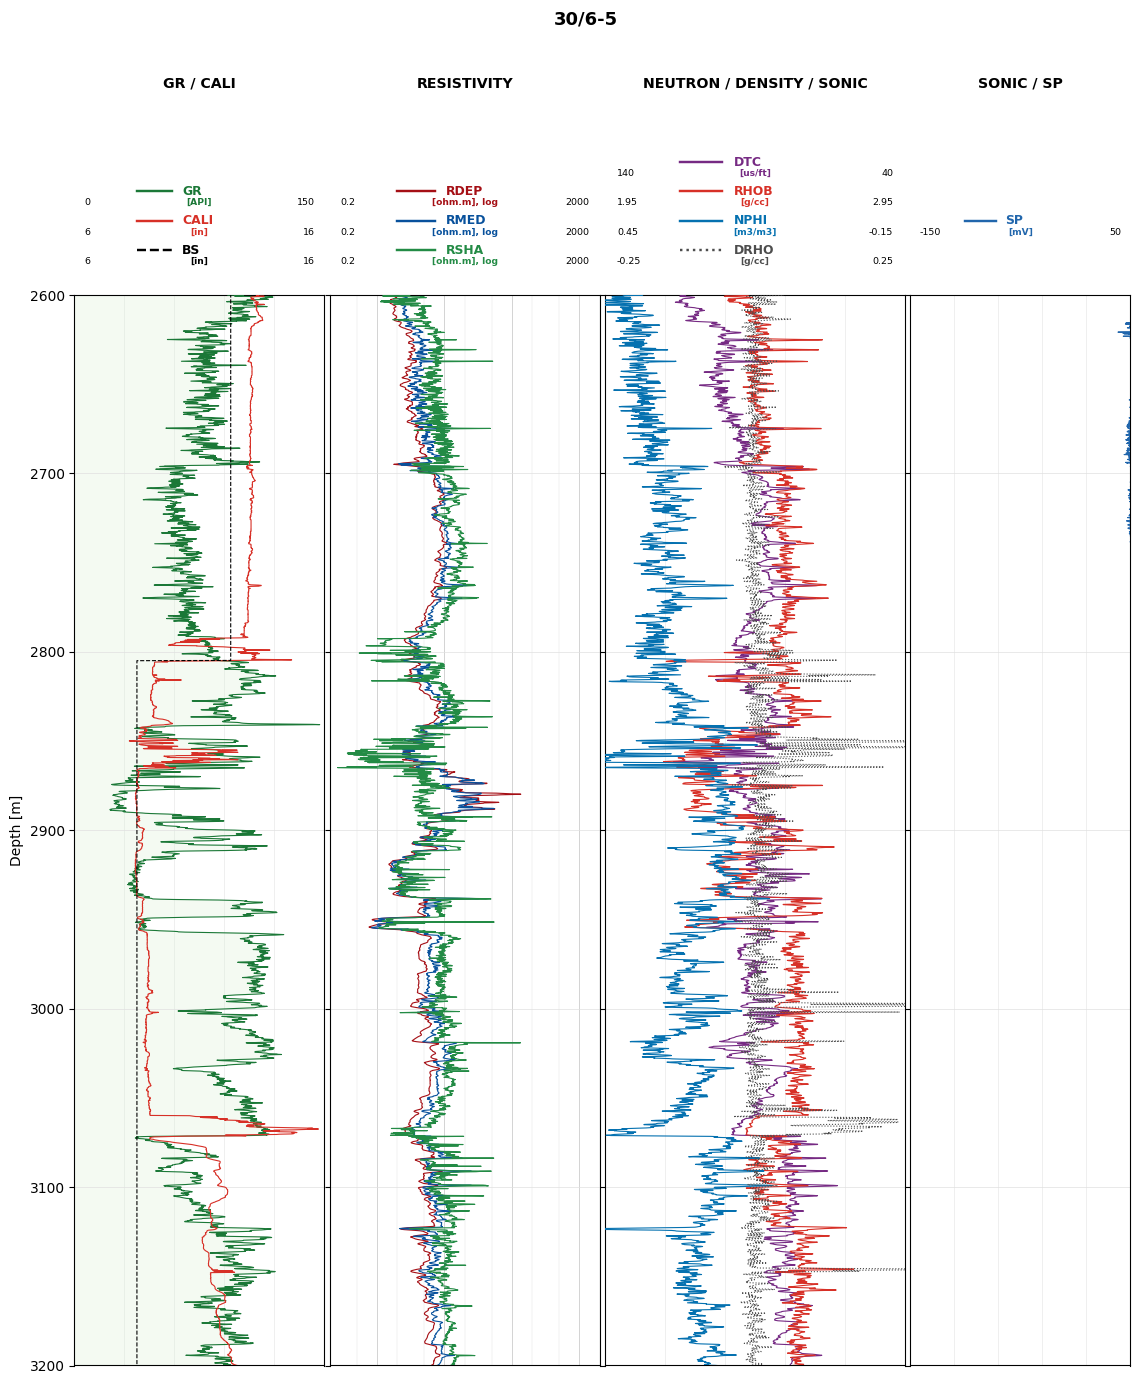

In [6]:
create_triple_combo(geo, depth_range=GEO_FULL)
plt.show()

## 3. The crossplot family

Crossplots move from depth-vs-value tracks to **value-vs-value** scatter, which is where
lithology, porosity model, and saturation logic become visible.

### 3a. Neutron-density crossplot

`create_nd_crossplot` plots NPHI against RHOB with lithology lines; points are coloured
by a third curve (default `GR`). Sandstone, limestone, and dolomite trends separate here,
and gas pulls points toward low apparent density / low neutron. We restrict to the PEF-live
interval where lithology work is valid on 30/6-5.

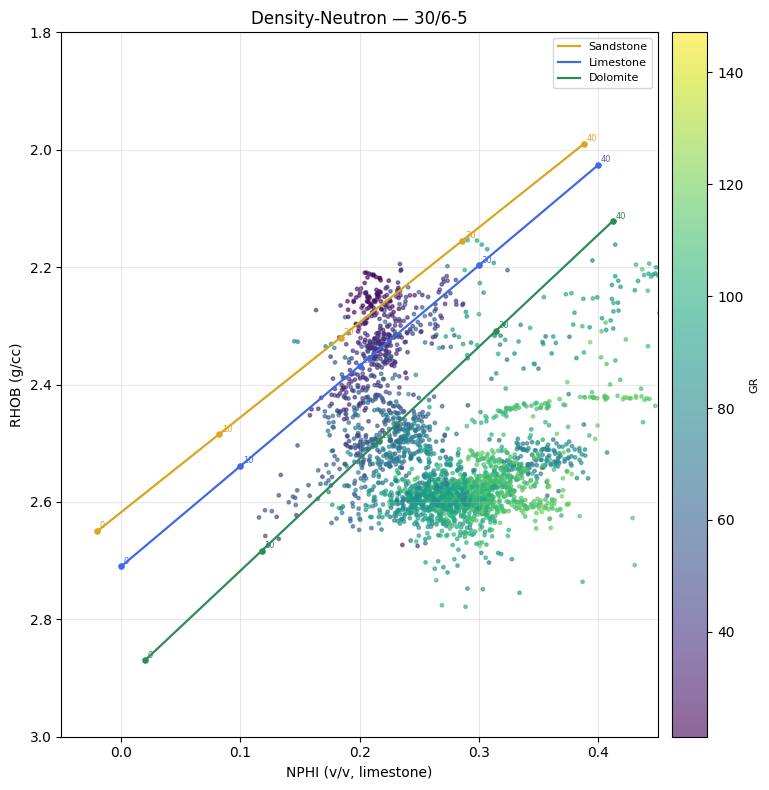

In [7]:
create_nd_crossplot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

### 3b. Pickett plot

`create_pickett_plot` plots `log(RT)` vs `log(PHIE)`. In a clean, water-bearing zone the
100%-water points fall on a straight line whose slope is the cementation exponent `m` and
whose intercept fixes `Rw`. Hydrocarbon points sit **above** the water line. We run it on
the Statfjord water sand (a hydrocarbon interval would give too few water points).

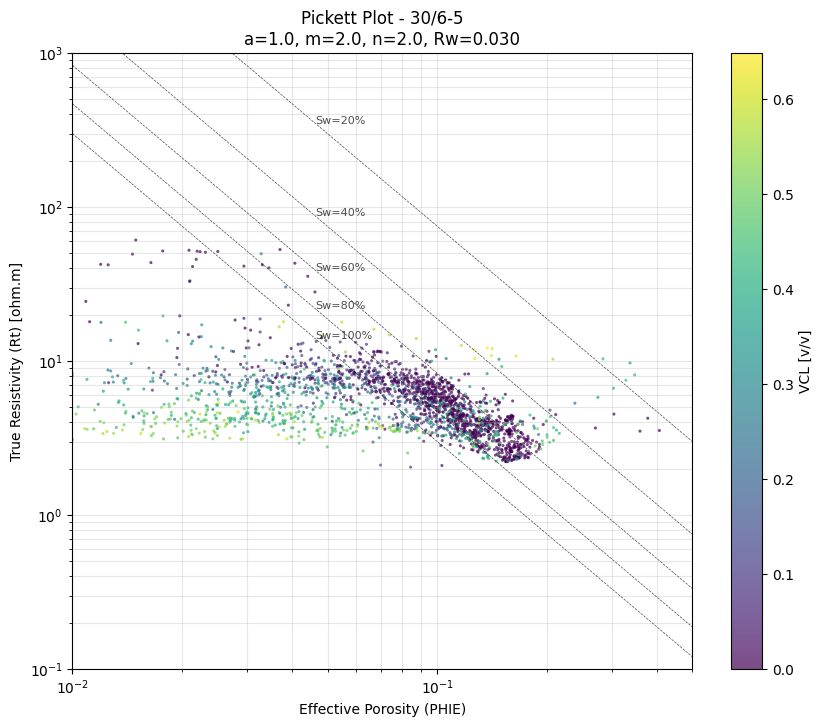

In [8]:
create_pickett_plot(
    geo, rw=0.03, phie_curve="PHIE", rt_curve="RDEP",
    color_curve="VCL", depth_range=GEO_WATER, a=1.0, m=2.0, n=2.0,
)
plt.show()

### 3c. Hingle plot

`create_hingle_plot` is the Pickett plot's linear-grid cousin: it linearises the Archie
relation so the water line and `Rw` can be read on ordinary axes. Same water interval,
same idea, different projection - useful when you want to fit the water line by eye.

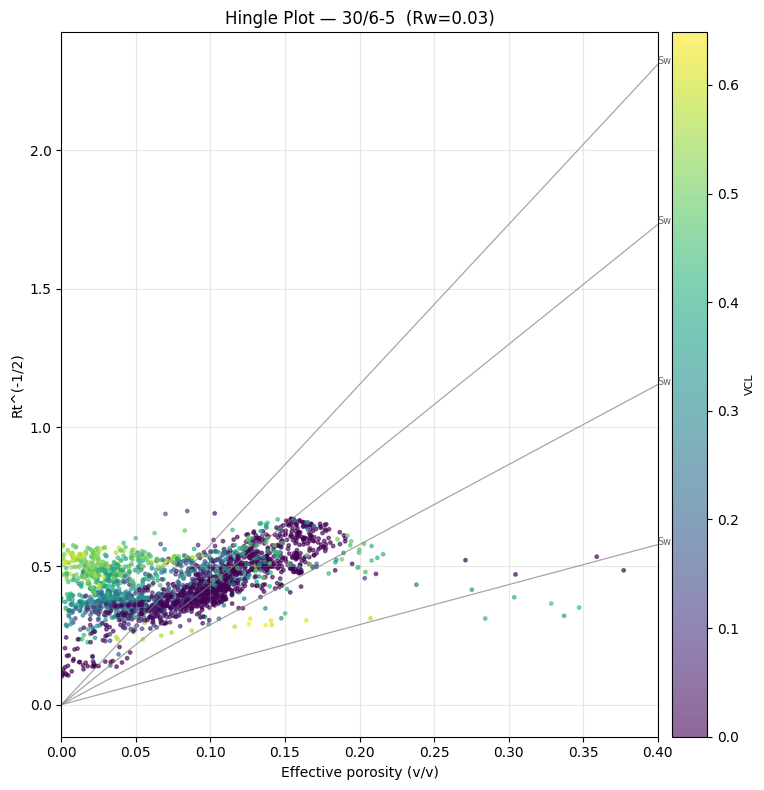

In [9]:
create_hingle_plot(
    geo, rw=0.03, m=2.0, n=2.0, phie_curve="PHIE", rt_curve="RDEP",
    color_curve="VCL", a=1.0, depth_range=GEO_WATER,
)
plt.show()

### 3d. M-N and MID lithology crossplots

`create_mn_plot` and `create_mid_plot` combine density, neutron, and sonic to identify
matrix mineralogy and flag secondary porosity / gas independent of a single crossplot.
Both need a sonic curve, which 30/6-5 has (`DTC`). Coloured by `GR`.

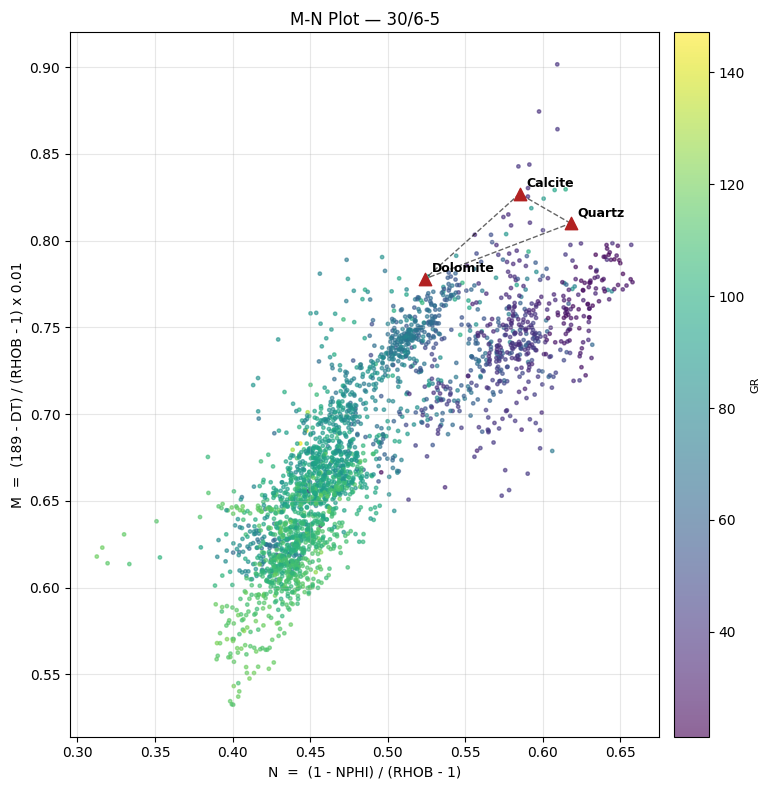

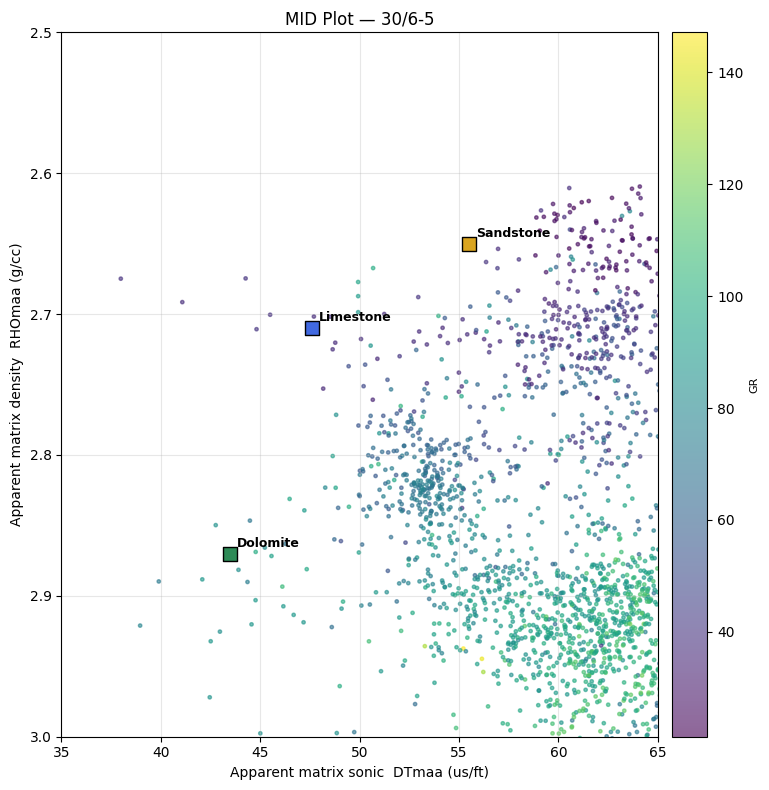

In [10]:
create_mn_plot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

create_mid_plot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

### 3e. Buckles plot

`create_buckles_plot` shows `PHIE` vs `SW`; points on a common `PHIE * SW = const`
hyperbola indicate a zone at **irreducible water** (constant bulk-volume water), which
predicts water-free production. Coloured by permeability. This is a carbonate reservoir
question, so we run it on HW-3.

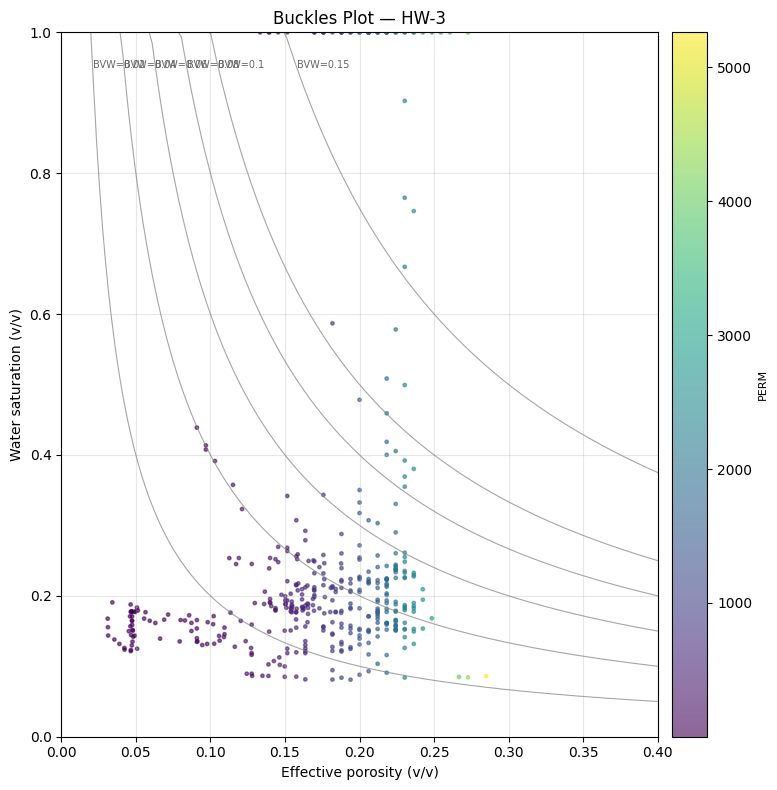

In [11]:
create_buckles_plot(carb, phie_curve="PHIE", sw_curve="SW", color_curve="PERM")
plt.show()

## 4. Specialist panels

### 4a. Flow-unit (RQI vs phi_z) plot

`create_flow_unit_plot` renders a Reservoir Quality Index / flow-zone-indicator analysis.
Compute the units with `calculate_flow_units(perm_k, phi_e)` (note: **permeability
first**), then hand the result straight to the plot. Distinct flow units appear as
parallel bands on the RQI-vs-porosity axes.

flow-unit result type: FlowUnitResult


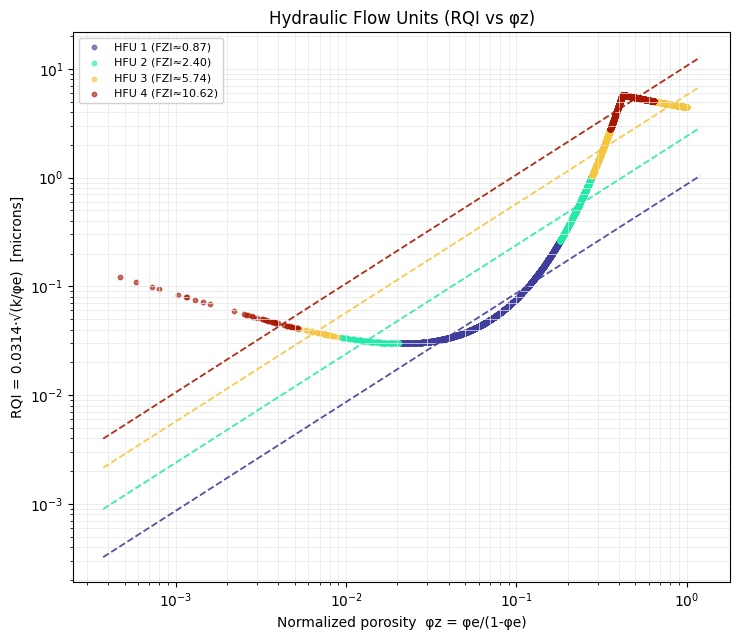

In [12]:
phie = geo.get("PHIE").data
perm = geo.get("PERM").data
fu = calculate_flow_units(perm, phie)          # perm_k first, then phi_e
print("flow-unit result type:", type(fu).__name__)

create_flow_unit_plot(result=fu)
plt.show()

### 4b. FMI panel

`create_fmi_panel` (covered in depth in notebook 16) belongs to the same visualization
suite. It takes a `BoreholeImageData`, orients it, equalizes, and renders. Here we feed a
small **illustrative synthetic** oriented image so the gallery is complete without a DLIS
file.

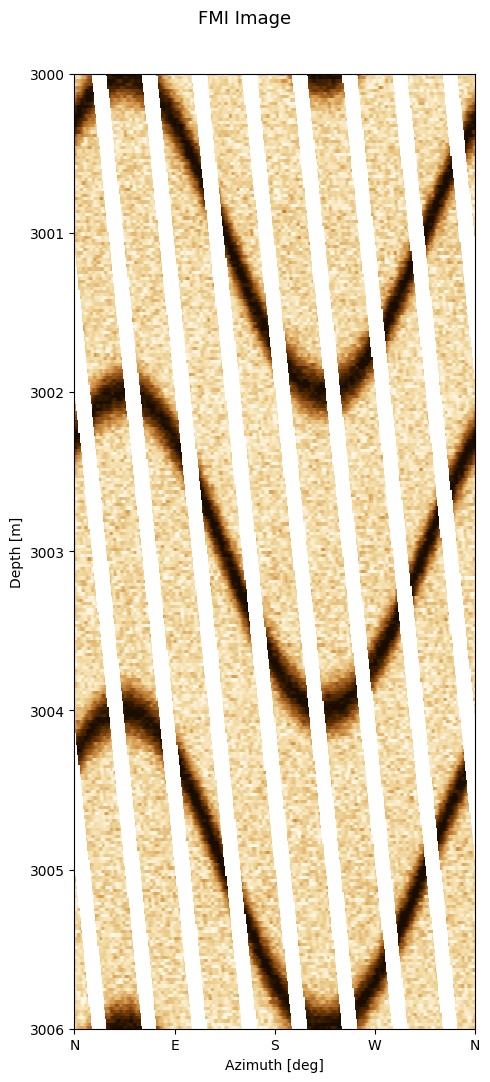

In [13]:
from petrophys.imaging import BoreholeImageData, with_navigation
from petrophys.imaging.fmi import ARRAY_ORDER, ARRAY_OFFSET_DEG, ARRAY_SPACING_DEG

# --- ILLUSTRATIVE synthetic FMI (see notebook 16 for the full explanation) ---
rng = np.random.default_rng(0)
n_d, nb = 300, 12
zd = np.linspace(3000.0, 3006.0, n_d)
p1az = np.mod(np.linspace(0, 90, n_d), 360.0)
half = 0.5 * ARRAY_SPACING_DEG * 0.70
cols = []
for name in ARRAY_ORDER:
    loc = np.linspace(-half, half, nb)
    az = np.deg2rad(np.mod(p1az[:, None] + ARRAY_OFFSET_DEG[name] + loc[None, :], 360.0))
    d = zd[:, None] + 1.0 * np.cos(az - np.deg2rad(45.0))
    bed = np.exp(-((np.mod(d, 2.0) - 1.0) ** 2) / 0.02)
    cols.append((0.5 - 0.4 * bed + 0.03 * rng.standard_normal(d.shape)).astype(np.float32))
img = np.concatenate(cols, axis=1)
fmi = BoreholeImageData.from_arrays(
    depth=zd, image=img, channel_names=list(ARRAY_ORDER),
    samples_per_channel=[nb] * len(ARRAY_ORDER), image_type="fmi_raw", depth_unit="m")
fmi = with_navigation(fmi, {"P1AZ": p1az})

create_fmi_panel(fmi, orient=True, equalize="dynamic")
plt.show()

### 4c. NMR panel

`create_nmr_panel` builds the standard CMR display (GR/QC, borehole, CMR porosity split
into bound/free fluid, NMR permeability, Swirr/T2). It needs NMR summary curves such as
`TCMR`, `CMFF`, `KTIM`; `has_nmr_curves(well)` tells you whether a well qualifies.

Neither teaching well carries NMR logs, so we attach a small **illustrative synthetic**
NMR curve set to a copy of 30/6-5 purely to render the panel.

30/6-5 has NMR curves already? -> False


after adding synthetic curves -> has NMR: True


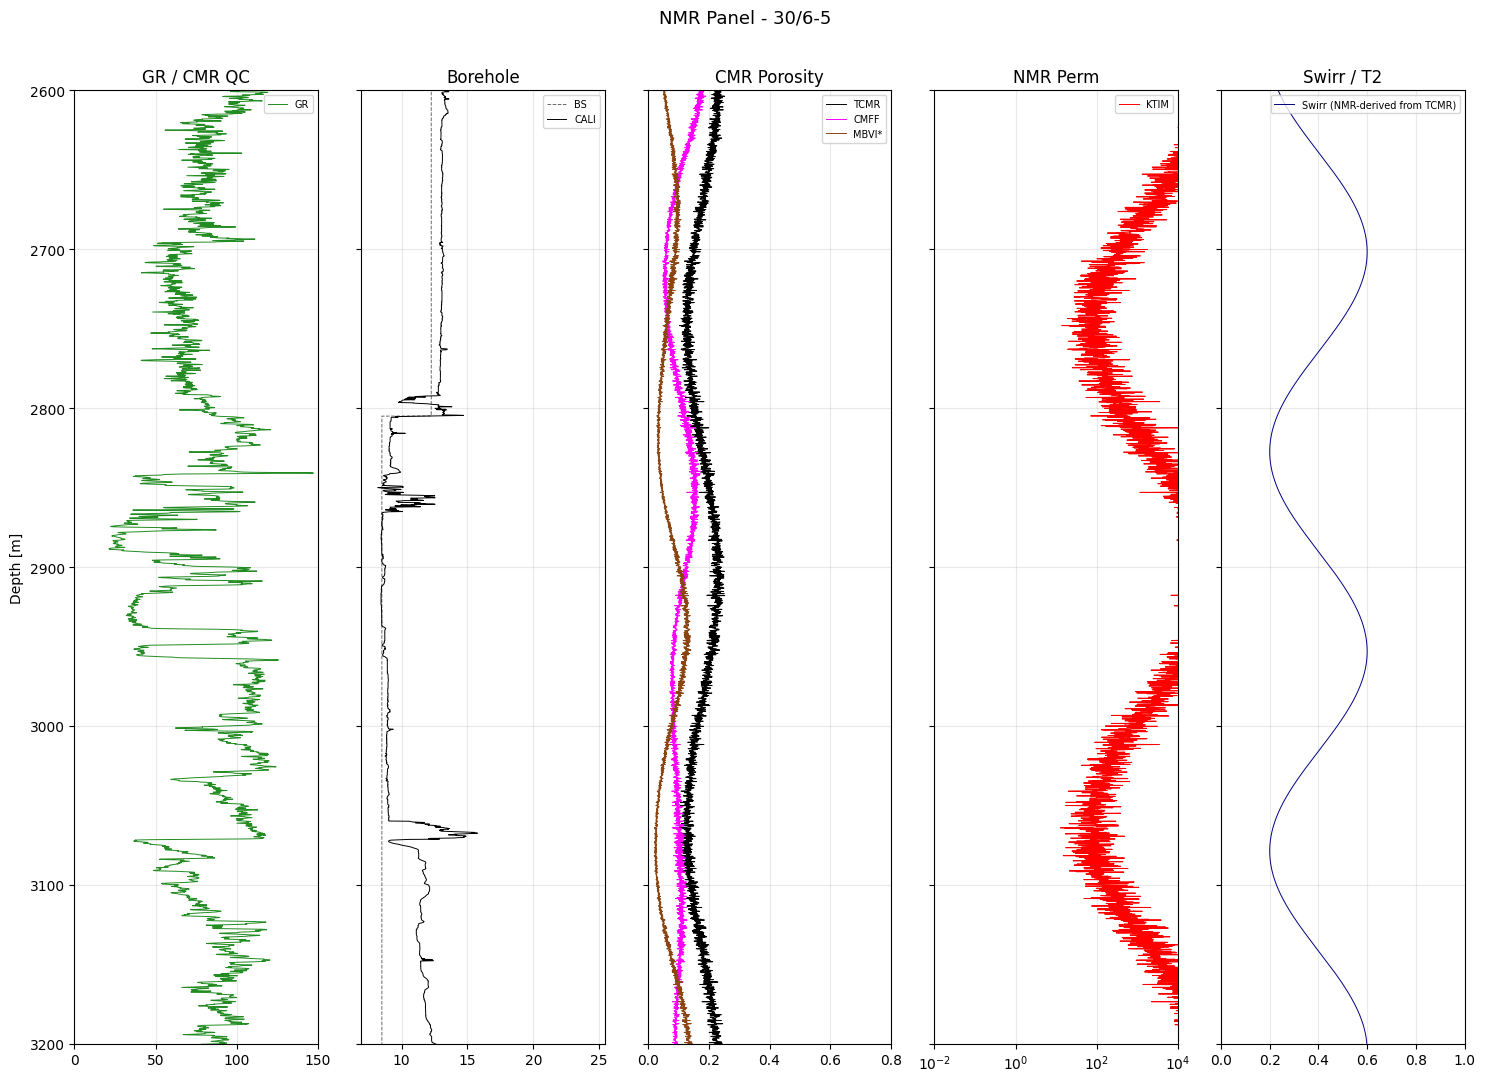

In [14]:
print("30/6-5 has NMR curves already? ->", has_nmr_curves(geo))

nmr_well = read_las(petrophys.sample("30_6-5"))
zd = nmr_well.depth
rng = np.random.default_rng(1)
tcmr = np.clip(0.18 + 0.05 * np.sin(zd / 50) + 0.01 * rng.standard_normal(zd.size), 0.02, 0.35)
cmff = tcmr * np.clip(0.60 + 0.20 * np.sin(zd / 40), 0.10, 0.90)
nmr_well.add_curve("TCMR", tcmr, unit="v/v", description="NMR total porosity (synthetic)")
nmr_well.add_curve("CMFF", cmff, unit="v/v", description="NMR free fluid (synthetic)")
nmr_well.add_curve("KTIM", 10 ** (30 * tcmr - 2), unit="mD", description="NMR Timur perm (synthetic)")
print("after adding synthetic curves -> has NMR:", has_nmr_curves(nmr_well))

create_nmr_panel(nmr_well, depth_range=GEO_FULL)
plt.show()

## 5. Zone flags and formation shading

`plot_zone_flags` renders discrete flag curves (net rock / reservoir / pay) as coloured
bars against depth - an at-a-glance summary of where the pay is. It returns
`(fig, axes)`.

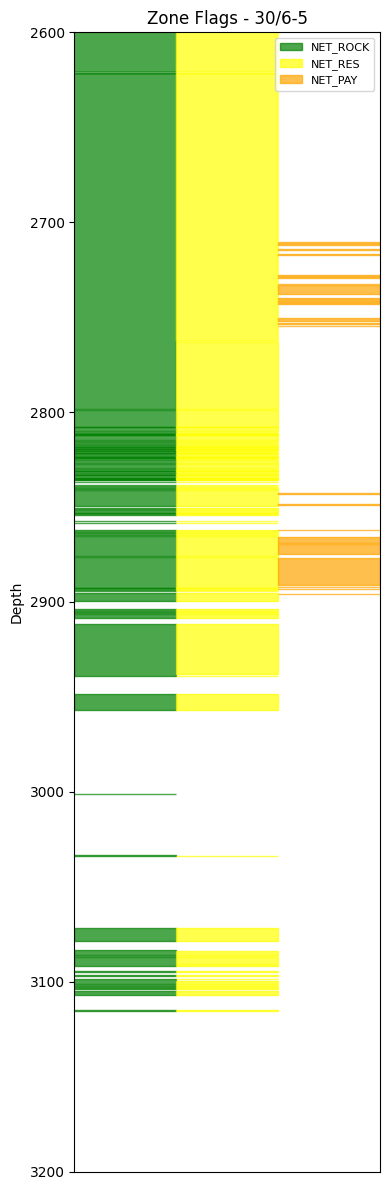

In [15]:
fig, ax = plot_zone_flags(
    geo, flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"], depth_range=GEO_FULL,
)
plt.show()

`add_zone_shading` decorates an existing axis with translucent depth bands - handy for
highlighting named intervals on any custom track. Each zone is a dict with `top`,
`bottom`, and styling keys.

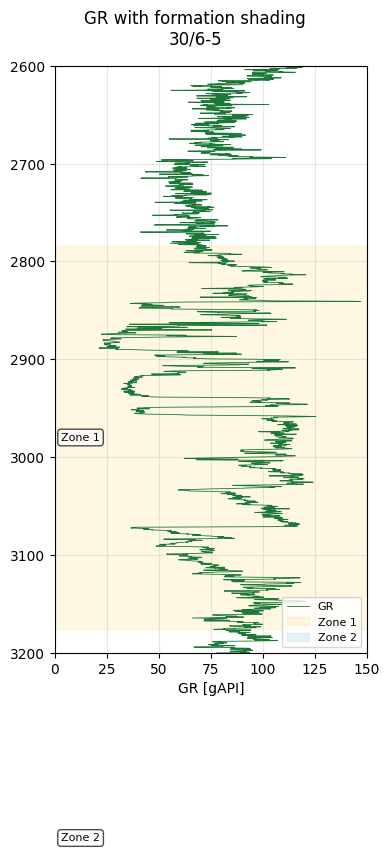

In [16]:
from petrophys.visualization import LogPlot

# Render GR with the library LogPlot, then decorate its axis with formation
# shading. add_zone_shading operates on any matplotlib axis, including the one
# LogPlot creates.
lp = LogPlot(geo, figsize=(4, 9))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "GR", color="#1b7837", linewidth=0.6, xlim=(0, 150))
lp.set_depth_range(top=GEO_FULL[0], bottom=GEO_FULL[1])
lp.add_title("GR with formation shading")

zones = [
    {"top": 2784.0, "bottom": 3176.0, "color": "#fee08b", "label": "Lithology-live (PEF)"},
    {"top": 3223.0, "bottom": 3556.0, "color": "#9ecae1", "label": "Statfjord water sand"},
]
add_zone_shading(lp.axes[0], zones, alpha=0.25)
lp.axes[0].legend(loc="lower right", fontsize=8)
lp.show()

## 6. Non-log analytics helpers

Beyond depth-track logs and crossplots, `petrophys.visualization` ships a small
set of **general analytics charts** for multi-well studies, model comparisons
and sensitivity work. They take plain arrays (or `Well` objects) so you never
hand-roll matplotlib:

- `create_multiwell_overlay` - one curve versus depth across several wells;
- `create_bar_comparison` - single or grouped ranking bars;
- `create_tornado_plot` - a sensitivity tornado about a base case;
- `create_histogram_comparison` - overlaid distributions;
- `create_line_comparison` - generic x versus many y-series lines.

We demonstrate each on real Geolink wells.

### 6a. Multi-well curve overlay

`create_multiwell_overlay(wells, curve, ...)` overlays one curve versus depth for
several wells on a shared axis - the standard cross-well QC view. With
`normalize=True` each curve is robustly min-max scaled to 0-1 so their shapes
compare directly regardless of absolute GR level.

wells with GR: ['30/6-5', '16/7-1', '25/5-1 Froey', '15/9-14']


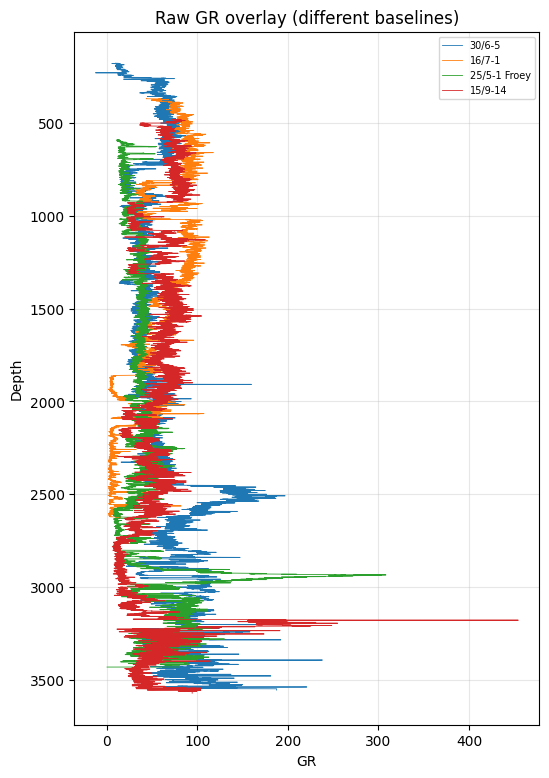

In [17]:
from petrophys.visualization import (
    create_multiwell_overlay, create_bar_comparison, create_tornado_plot,
    create_histogram_comparison, create_line_comparison,
)

# Load a few Geolink wells (all in metres) that carry GR.
field_names = ["30_6-5", "16_7-1", "25_5-1", "15_9-14"]
field_wells = [read_las(petrophys.sample(n)) for n in field_names]
field_wells = [w for w in field_wells if w.has_curve("GR")]
print("wells with GR:", [w.name for w in field_wells])

fig, ax = create_multiwell_overlay(
    field_wells, "GR", normalize=False,
    title="Raw GR overlay (different baselines)", figsize=(6, 9),
)
plt.show()

### 6b. Grouped/ranking bar comparison

`create_bar_comparison(categories, values, ...)` draws single or grouped bars.
`values` may be a 1-D sequence or a `{series: values}` mapping for grouped bars;
`sort_by` ranks the categories by a chosen series. Here we rank wells by their
mean GR and, as a second series, their GR standard deviation.

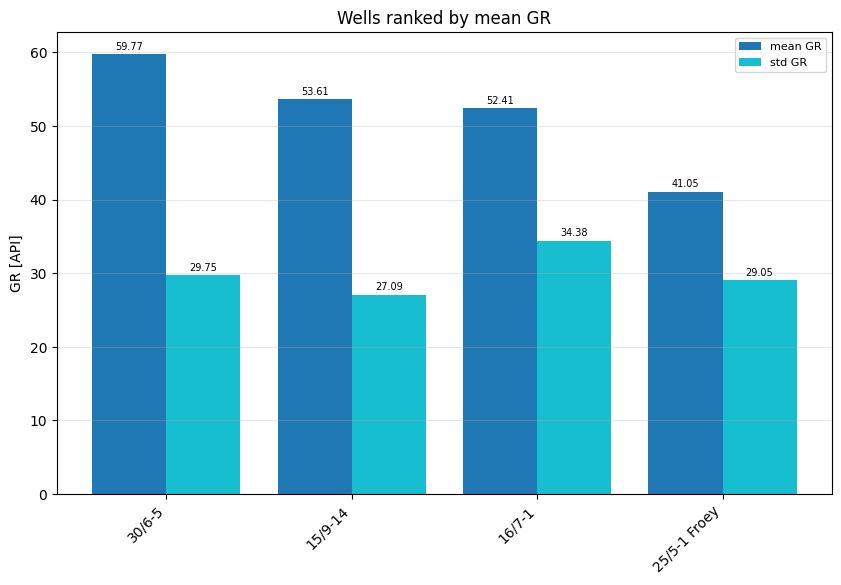

In [18]:
cats = [w.name for w in field_wells]
mean_gr = [float(np.nanmean(w.get("GR").data)) for w in field_wells]
std_gr = [float(np.nanstd(w.get("GR").data)) for w in field_wells]

fig, ax = create_bar_comparison(
    cats, {"mean GR": mean_gr, "std GR": std_gr},
    sort_by=0, descending=True, value_labels=True,
    ylabel="GR [API]", title="Wells ranked by mean GR",
)
plt.show()

### 6c. Sensitivity tornado

`create_tornado_plot(labels, low, high, base, ...)` shows how an outcome swings
when each input takes its low/high setting, sorted widest-span-on-top. Below we
sweep an Archie water-saturation calculation (single representative point) over
+/- ranges of `Rw`, `m`, `n` and `PHIE`, and plot the resulting Sw span.

base Sw = 0.194


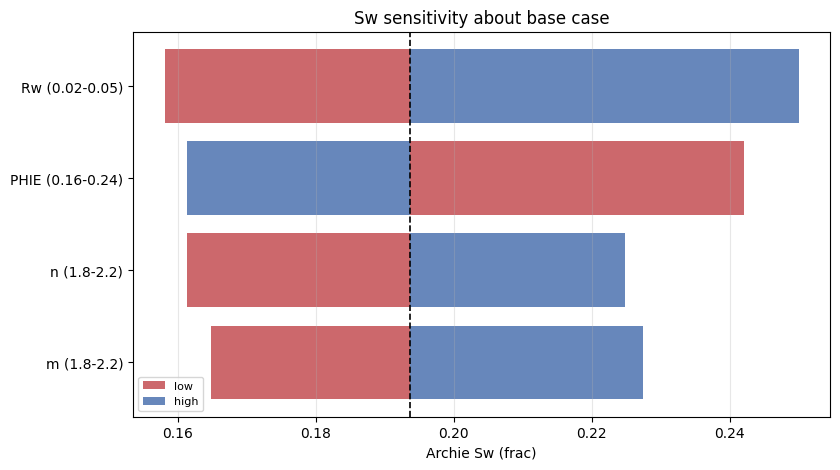

In [19]:
from petrophys.petrophysics.saturation import archie

# Representative reservoir point on 30/6-5.
base = dict(rt=20.0, phie=0.20, rw=0.03, a=1.0, m=2.0, n=2.0)
def sw(**kw):
    p = dict(base); p.update(kw)
    return float(archie(rt=p["rt"], rw=p["rw"], phi=p["phie"],
                        a=p["a"], m=p["m"], n=p["n"]))

sw_base = sw()
params = {
    "Rw (0.02-0.05)":  (sw(rw=0.02), sw(rw=0.05)),
    "m (1.8-2.2)":     (sw(m=1.8),   sw(m=2.2)),
    "n (1.8-2.2)":     (sw(n=1.8),   sw(n=2.2)),
    "PHIE (0.16-0.24)":(sw(phie=0.16), sw(phie=0.24)),
}
labels = list(params)
low = [params[k][0] for k in labels]
high = [params[k][1] for k in labels]
print("base Sw = %.3f" % sw_base)

fig, ax = create_tornado_plot(
    labels, low, high, base=sw_base,
    xlabel="Archie Sw (frac)", title="Sw sensitivity about base case",
)
plt.show()

### 6d. Histogram comparison

`create_histogram_comparison({label: array, ...})` overlays distributions on a
common bin grid. A classic use is comparing a curve's spread across wells (or
before/after normalization); here we compare each well's GR distribution.

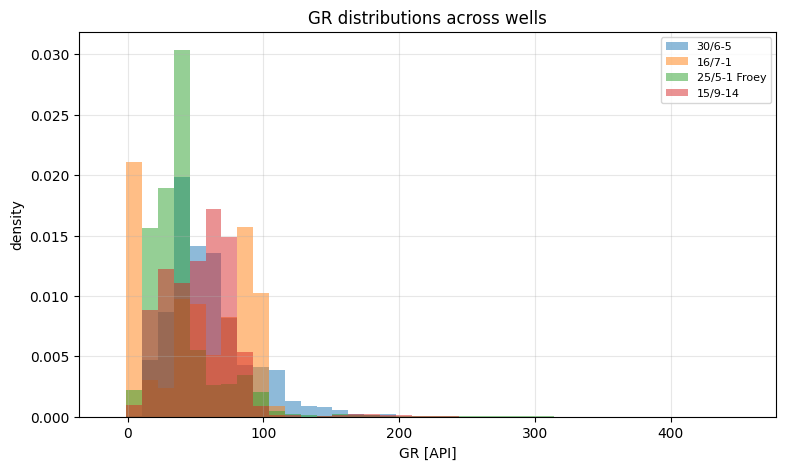

In [20]:
gr_dists = {w.name: w.get("GR").data for w in field_wells}
fig, ax = create_histogram_comparison(
    gr_dists, bins=40, density=True,
    xlabel="GR [API]", title="GR distributions across wells",
)
plt.show()

### 6e. Line comparison (transfer functions)

`create_line_comparison(x, {label: y, ...})` is the generic x-versus-many-series
plotter for things that are not depth tracks: transfer functions, temperature
profiles, and similar. Here we compare the common **Vcl-from-GR transfer
functions** (linear vs the two Larionov forms and Clavier) over the full IGR
range.

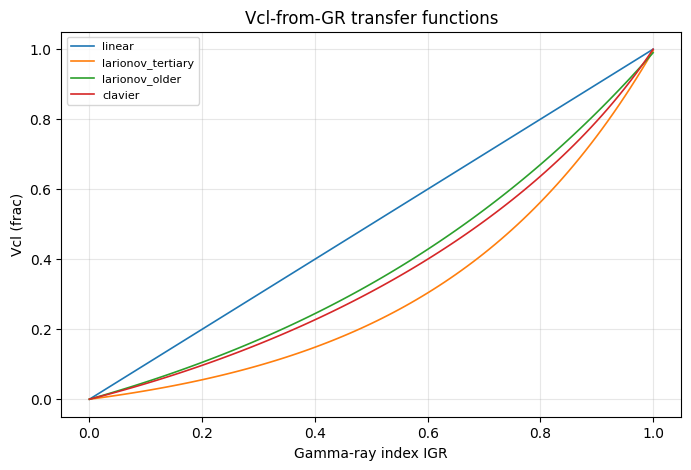

In [21]:
from petrophys.clay_volume import vcl_from_gr

igr = np.linspace(0.0, 1.0, 101)     # gamma-ray index (0 clean -> 1 shale)
gr = igr * 100.0                     # map onto a 0-100 API scale (gr_min=0, gr_max=100)
transfer = {
    "linear":            vcl_from_gr(gr, 0.0, 100.0, method="linear"),
    "larionov_tertiary": vcl_from_gr(gr, 0.0, 100.0, method="larionov_tertiary"),
    "larionov_older":    vcl_from_gr(gr, 0.0, 100.0, method="larionov_older"),
    "clavier":           vcl_from_gr(gr, 0.0, 100.0, method="clavier"),
}
fig, ax = create_line_comparison(
    igr, transfer,
    xlabel="Gamma-ray index IGR", ylabel="Vcl (frac)",
    title="Vcl-from-GR transfer functions",
)
plt.show()

## Pitfalls & parameter choices

- **`create_log_viewer` returns a `LogViewer`, not a figure.** Call `.create(...)` to get
  `(fig, axes)`; close it with `.close()` to free memory in loops.
- **`auto` template is curve-driven.** It silently drops tracks whose curves are absent -
  great for robustness, but check `create_adaptive_log_viewer_template(well)` if a track
  you expected is missing.
- **Pickett/Hingle need water points.** Run them on a **water-bearing** interval; a pure
  hydrocarbon zone has too few 100%-water points and the water-line fit degrades.
- **`calculate_flow_units(perm_k, phi_e)` takes permeability first.** Swapping the
  arguments silently produces nonsense bands.
- **Lithology crossplots need the right curves live.** On 30/6-5, `PEF` and lithology work
  are only valid in ~2784-3176 m; outside that the points are unconstrained.
- **NMR / FMI panels need the right inputs** (`has_nmr_curves`, a navigation curve). The
  synthetic data here is illustrative only - never interpret it as real rock.

## Recap

- The **template log viewer** (named or `auto`) is your general-purpose multi-track
  display; the **triple combo** is the fast first look.
- The **crossplot family** each answers a specific question: N-D for lithology/gas,
  Pickett/Hingle for `Rw`/`m` and the water line, M-N/MID for matrix mineralogy, Buckles
  for irreducible-water/producibility.
- **Specialist panels** cover flow units, FMI images, and NMR displays.
- **Zone flags** and **formation shading** annotate results directly on depth.

## Try it yourself

> **Exercise 1.** Render `create_log_viewer(geo, template_defaults="petrophysics")` and
> compare its track layout with `geolink_full`. Which curves each template emphasises tells
> you its intended audience.
>
> **Exercise 2.** Re-run the Pickett plot with `m=1.8` and `m=2.2`. How does the assumed
> cementation exponent move the water line, and hence computed `Sw`?
>
> **Exercise 3.** Build a Buckles plot on the clastic well `geo` over `GEO_FULL`. Do the
> points hug a single `PHIE*SW` hyperbola (irreducible) or scatter (transition zone)?

## What's next

Continue with **18_multiwell_field_study.ipynb**, where these single-well plots scale up:
we batch-process the 17-well Costa field, normalise logs across wells, and build a
cross-well comparison table and summary figure.